# Visão computacional na faixa de pedestres: travessias, conflitos e PCD

**Spec:** `docs/specs/2026-11-12-visao-pedestres-design.md` · **Código:** `src/visao/visao.py` (funções testadas) e
`src/visao/detector.py` (YOLO-World + ByteTrack) · **Testes:** `tests/test_visao.py`.

**O que este notebook faz:** roda o detector de vocabulário aberto **YOLO-World** (sem treino) com rastreamento
**ByteTrack** num vídeo público de faixa de pedestres e mede:
- **travessias:** duração e velocidade de cada pessoa, comparadas aos **1,2 m/s** que os semáforos de São Paulo
  supõem (Duim et al., 2017: 97,8% dos idosos de SP andam mais devagar);
- **conflitos** veículo × pedestre (quase-acidentes) e **bloqueios** da faixa;
- **pessoas com deficiência ou mobilidade reduzida** (cadeira de rodas, andador, muleta, bengala). O desempenho do
  detector nessas classes é avaliado num conjunto de imagens reais com licença livre.

**Base de demonstração (regra 8 da GS):** o vídeo é uma faixa de pedestres de dia, com câmera fixa, ao que tudo indica
na **Cidade do México** (Pexels, de Anya Juárez Tenorio, licença Pexels de uso livre). Não é o Largo da Concórdia. O
primeiro vídeo testado (Shibuya, Tóquio) foi descartado: era uma multidão densa demais para o detector separar as
pessoas, como mostra o diagnóstico em `data/raw/video/FONTE.md`, junto com a fonte, a licença e os outros candidatos
descartados.

**Privacidade (LGPD):** nada de reconhecimento facial. Todo quadro salvo passa por `borrar` (cabeças e placas
pixelizadas), e o banco guarda só números e tempos.

## 1. Configuração

In [1]:
from pathlib import Path
import sys, json, time, sqlite3, csv, warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="torch")   # aviso do torch.jit no Python 3.14 (traz caminho local)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
sys.path.insert(0, str(ROOT / "src" / "visao"))
import visao as vs
import detector

EVID = ROOT / "docs" / "evidencias" / "estudo_b"; EVID.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"
VIDEO = ROOT / "data" / "raw" / "video" / "cdmx_faixa_pexels_25775484.mp4"
VIDEO_ID = "cdmx_pexels_25775484"
CACHE = PROCESSED / "visao_deteccoes_cdmx.parquet"     # só caixas e números, nenhuma imagem
A_CADA = 1                 # todos os quadros: com 1 a cada 2, o rastreador fragmentava as pessoas (5 × 11 travessias concluídas)
CONF_MIN_GERAL = 0.25      # pessoas e veículos abaixo disso são descartados (os auxílios usam vs.CONF_MIN_AUXILIO)

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.edgecolor": "#bdbcb6",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

if not VIDEO.exists():
    raise FileNotFoundError(f"baixe o vídeo indicado em {VIDEO.parent / 'FONTE.md'} para {VIDEO}")
FPS, LARG, ALT, _ = vs.ler_video(VIDEO)
faixa = vs.Faixa.carregar(ROOT / "src" / "visao" / "faixa_cdmx.json").para_resolucao(LARG, ALT)
print(f"vídeo: {LARG}×{ALT}, {FPS:.1f} fps | faixa: {len(faixa.poligono)} vértices, {faixa.comprimento_m} m (estimado)")

vídeo: 1080×1920, 30.0 fps | faixa: 4 vértices, 6.7 m (estimado)


## 2. Detecção e rastreamento

O YOLO-World recebe a lista de classes **por texto**: pessoa, veículos, bicicleta, auxílios de mobilidade e placa.
O ByteTrack dá um identificador a cada objeto e o mantém de quadro em quadro. Na primeira execução as detecções vão
para um parquet (cache); depois o notebook só lê.

In [2]:
def rodar_detector():
    t0, linhas, n = time.time(), [], 0
    for q, img, dets in detector.detectar(VIDEO, a_cada=A_CADA):
        n += 1
        linhas += [{"quadro": d.quadro, "classe": d.classe, "x1": d.caixa[0], "y1": d.caixa[1], "x2": d.caixa[2],
                    "y2": d.caixa[3], "conf": d.conf, "track_id": d.track_id} for d in dets]
    df = pd.DataFrame(linhas)
    df.attrs["seg"], df.attrs["quadros"] = time.time() - t0, n
    return df

if CACHE.exists():
    det_df = pd.read_parquet(CACHE)
    meta = json.loads((CACHE.with_suffix(".json")).read_text(encoding="utf-8"))
else:
    det_df = rodar_detector()
    meta = {"segundos": det_df.attrs["seg"], "quadros_processados": det_df.attrs["quadros"], "a_cada": A_CADA}
    det_df.to_parquet(CACHE, index=False)
    CACHE.with_suffix(".json").write_text(json.dumps(meta), encoding="utf-8")
FPS_PROC = meta["quadros_processados"] / meta["segundos"]
print(f"{meta['quadros_processados']} quadros processados em {meta['segundos']:.0f} s → {FPS_PROC:.1f} quadros/s em CPU "
      f"(o vídeo tem {FPS:.0f} fps; tempo real exigiria {FPS / A_CADA:.0f} quadros/s)")

auxiliar = det_df["classe"].isin(vs.AUXILIOS | {"license plate"})
# LGPD: pessoas com confiança baixa saem da ANÁLISE, mas continuam sendo BORRADAS (regiões extras de privacidade, que
# não viram caixa nem rótulo). Na dúvida, borrar mais.
_baixa = det_df[(det_df["classe"] == "person") & (det_df["conf"] < CONF_MIN_GERAL)]
PRIV_EXTRA = {}
for r in _baixa.itertuples():
    PRIV_EXTRA.setdefault(int(r.quadro), []).append(vs.Deteccao(int(r.quadro), "person", (r.x1, r.y1, r.x2, r.y2), float(r.conf), None))
n_pessoas_total = int((det_df["classe"] == "person").sum())
det_df = det_df[auxiliar | (det_df["conf"] >= CONF_MIN_GERAL)].reset_index(drop=True)
dets = [vs.Deteccao(int(r.quadro), r.classe, (r.x1, r.y1, r.x2, r.y2), float(r.conf),
                    None if pd.isna(r.track_id) else int(r.track_id)) for r in det_df.itertuples()]
# Condutores de moto/bicicleta são detectados como "person": saem das análises de pedestre, mas continuam na lista
# usada para BORRAR (a cabeça deles também é protegida).
dets_todas = dets
cobertas = sum(d.classe == "person" for d in dets_todas) + sum(len(v) for v in PRIV_EXTRA.values())
assert cobertas == n_pessoas_total, "toda detecção de pessoa precisa entrar no borrão"
print(f"borrão: {cobertas} de {n_pessoas_total} detecções de pessoa ({len(_baixa)} de confiança baixa, só borradas)")
dets = vs.sem_condutores(dets_todas)
print(f"pessoas descartadas como condutores de moto/bicicleta: {sum(d.classe == 'person' for d in dets_todas) - sum(d.classe == 'person' for d in dets)} detecções")
resumo = det_df.groupby("classe").agg(deteccoes=("quadro", "size"), objetos_rastreados=("track_id", "nunique"),
                                      confianca_mediana=("conf", "median")).sort_values("deteccoes", ascending=False)
resumo.round(2)

1655 quadros processados em 608 s → 2.7 quadros/s em CPU (o vídeo tem 30 fps; tempo real exigiria 30 quadros/s)
borrão: 5243 de 5243 detecções de pessoa (420 de confiança baixa, só borradas)
pessoas descartadas como condutores de moto/bicicleta: 454 detecções


,deteccoes,objetos_rastreados,confianca_mediana
classe,,,
car,7376,60,0.52
person,4823,100,0.64
motorcycle,453,19,0.65
bicycle,148,5,0.74


**Leitura:** em 55 s de vídeo (1.655 quadros), o YOLO-World achou pessoas em 4.823 detecções, agrupadas pelo
rastreador em 100 identificadores, e carros em 7.376 (60 identificadores). 100 identificadores não são 100 pessoas:
quando alguém some atrás de um carro e reaparece, pode ganhar um número novo (fragmentação). 454 detecções de pessoa
eram condutores de moto ou bicicleta e saíram da análise de pedestres, mas continuam borradas. O ritmo em CPU foi de
2,7 quadros/s, cerca de 11 vezes mais lento que o tempo real (30 quadros/s): numa câmera de verdade, seria preciso GPU
ou analisar 1 quadro a cada poucos.

## 3. Travessias

Cada pessoa rastreada passa pela máquina de estados de `vs.travessias` (spec §5): a entrada e a saída só contam
depois de 3 quadros seguidos, sumiços de até 1 s não quebram a travessia, a troca de identificador gera duas
travessias "não concluídas", e a volta pelo mesmo lado é "retorno". Só as **concluídas** entram em médias. A
velocidade é o comprimento estimado do trecho visível da faixa (~6,7 m) dividido pela duração. **Atenção:** o quadro
vertical não mostra a rua inteira, então a travessia medida é a do trecho visível, não de calçada a calçada.

In [3]:
PCD = vs.pessoas_pcd(dets)
trav = pd.DataFrame([t.__dict__ for t in vs.travessias(dets, faixa, FPS, PCD)])
print(f"pessoas com auxílio de mobilidade (PCD) detectadas no vídeo: {len(PCD)}")
if trav.empty:
    print("nenhuma travessia")
else:
    display(trav["status"].value_counts().rename("travessias").to_frame())
    ok = trav[trav["status"] == "concluida"]
    if len(ok):
        print(f"concluídas: {len(ok)} | duração mediana {ok['duracao_s'].median():.1f} s | velocidade mediana "
              f"{ok['velocidade_ms'].median():.2f} m/s | abaixo de 1,2 m/s: {ok['abaixo_1_2_ms'].mean():.0%}")

pessoas com auxílio de mobilidade (PCD) detectadas no vídeo: 0


,travessias
status,
nao_concluida,22
concluida,11
inicio_desconhecido,10
retorno,3


concluídas: 11 | duração mediana 4.5 s | velocidade mediana 1.48 m/s | abaixo de 1,2 m/s: 0%


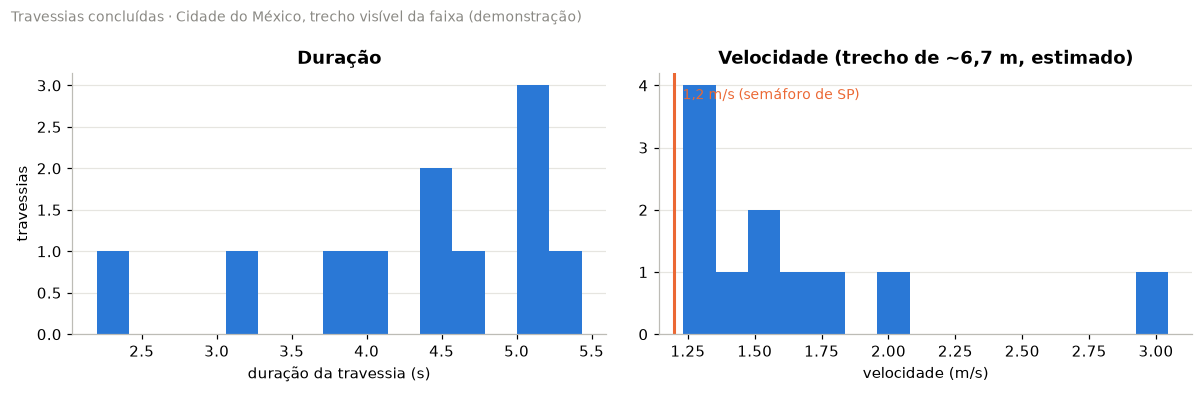

In [4]:
ok = trav[trav["status"] == "concluida"] if not trav.empty else trav
if len(ok):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].hist(ok["duracao_s"], bins=15, color=AZUL)
    axes[0].set_xlabel("duração da travessia (s)"); axes[0].set_ylabel("travessias"); axes[0].set_title("Duração")
    axes[1].hist(ok["velocidade_ms"], bins=15, color=AZUL)
    axes[1].axvline(vs.VEL_IDOSO_MS, color=LARANJA, lw=2)
    axes[1].text(vs.VEL_IDOSO_MS, axes[1].get_ylim()[1] * 0.9, "  1,2 m/s (semáforo de SP)", color=LARANJA, fontsize=9)
    axes[1].set_xlabel("velocidade (m/s)"); axes[1].set_title("Velocidade (trecho de ~6,7 m, estimado)")
    for ax in axes: ax.grid(axis="x", visible=False)
    fig.suptitle("Travessias concluídas · Cidade do México, trecho visível da faixa (demonstração)", x=0.01, ha="left", fontsize=9, color=CINZA)
    fig.tight_layout(); fig.savefig(EVID / "07_travessias.png", dpi=150, bbox_inches="tight", facecolor="white"); plt.show()

**Leitura:** das 46 travessias registradas, 11 foram concluídas (a pessoa entrou por um lado e saiu pelo
outro), com duração mediana de 4,5 s e velocidade mediana de 1,48 m/s. Nenhuma ficou abaixo de 1,2 m/s, a velocidade
usada como referência para idosos e pessoas com mobilidade reduzida: neste trecho e nestes 55 s, todo mundo que
completou a travessia teria tempo de sobra num semáforo calculado para 1,2 m/s. As 22 "não concluídas" e as 10 com
início desconhecido são, na maioria, efeito do enquadramento (o quadro vertical corta a faixa) e da fragmentação do
rastreamento, não pessoas que desistiram. Por isso a velocidade só é calculada para as concluídas.

## 4. Conflitos, bloqueios e bicicletas

In [5]:
conf_l = vs.conflitos(dets, faixa, FPS, PCD)
bloq_l = vs.bloqueios(dets, faixa, FPS)
# para a anotação visual: veículo em conflito fica vermelho, com a velocidade, por 1 s a partir do conflito
AUXILIOS = vs.auxilios_por_pessoa(dets)
CONF_POR_QUADRO = {}
for c in conf_l:
    for q in range(c.quadro, c.quadro + int(FPS)):
        CONF_POR_QUADRO.setdefault(q, {})[c.track_veiculo] = c.velocidade_kmh
if conf_l:
    display(pd.DataFrame([c.__dict__ for c in conf_l]))
duracao_h = (det_df["quadro"].max() + 1) / FPS / 3600
tab = pd.DataFrame({"eventos no vídeo": [len(conf_l), sum(c.severidade == "alta" for c in conf_l), len(bloq_l),
                                         vs.contagem_bicicletas(dets, faixa)]},
                   index=["conflitos veículo × pedestre", "  dos quais com PCD (severidade alta)", "bloqueios da faixa",
                          "bicicletas na faixa"])
tab["por hora (extrapolado)"] = (tab["eventos no vídeo"] / duracao_h).round(0)
print(f"duração analisada: {duracao_h * 60:.1f} min")
tab

,quadro,track_veiculo,classe_veiculo,track_pedestre,severidade,velocidade_kmh
0,803,330,motorcycle,232,normal,2.2
1,803,330,motorcycle,302,normal,2.2
2,803,330,motorcycle,320,normal,2.2
3,803,330,motorcycle,328,normal,2.2
4,816,330,motorcycle,339,normal,4.5
5,829,330,motorcycle,360,normal,6.9
6,834,330,motorcycle,314,normal,8.0


duração analisada: 0.9 min


,eventos no vídeo,por hora (extrapolado)
conflitos veículo × pedestre,7,457.0
dos quais com PCD (severidade alta),0,0.0
bloqueios da faixa,2,131.0
bicicletas na faixa,1,65.0


**Leitura:** os 7 conflitos são **um único episódio**: a moto 330, andando devagar (2 a 8 km/h) entre
pedestres que atravessavam, por volta de 27 s. Como o conflito é registrado por par veículo × pedestre, uma moto
passando no meio de quatro pessoas gera quatro registros no mesmo quadro. Nenhum foi de severidade alta (sem pedestre
com auxílio de mobilidade e sem veículo a 30 km/h ou mais). A extrapolação "por hora" (457 conflitos) parte de menos de
1 minuto de vídeo e de um só episódio: serve para mostrar a unidade da métrica, **não** como estimativa. Os 2 bloqueios
foram carros parados sobre a faixa.

## 5. Conferência visual (precisão e recall aproximados)

Doze quadros sorteados, com a faixa e as caixas desenhadas e **cabeças borradas**, numa folha de contato. Conto
**só as pessoas com os pés dentro da faixa**: a cena tem dezenas de pessoas por quadro, e contar todas à mão não
seria confiável. Para cada quadro anoto: pessoas na faixa com caixa (acerto), caixas sem pessoa (falso alarme) e
pessoas sem caixa (perda). As anotações ficam em `docs/evidencias/estudo_b/07_conferencia_manual.csv`.

In [6]:
import cv2
rng = np.random.default_rng(42)
quadros_det = np.sort(det_df["quadro"].unique())
amostra = set(rng.choice(quadros_det[quadros_det > 60], size=12, replace=False).tolist())
_, _, _, gen = vs.ler_video(VIDEO)
miniaturas = {}
P = np.array(faixa.poligono, np.int32)
for i, img in enumerate(gen):
    if i in amostra:
        dq = [d for d in dets_todas if d.quadro == i]
        miniaturas[i] = vs.anotar(img, dq, faixa, AUXILIOS, CONF_POR_QUADRO.get(i), privadas_extra=PRIV_EXTRA.get(i, []))   # borra antes, anota por cima
    if i > max(amostra):
        break
# recorte em volta da faixa (onde estão as pessoas), largura toda: dá para contar cada pessoa
ys = [y for _, y in faixa.poligono]
y_ini, y_fim = max(0, int(min(ys)) - 260), min(ALT, int(max(ys)) + 60)
def miniatura(q):
    m = miniaturas[q][y_ini:y_fim]
    m = cv2.resize(m, (540, int(540 * m.shape[0] / m.shape[1])))
    return cv2.putText(m, f"quadro {q}", (6, 22), 0, 0.7, (0, 255, 255), 2)
folha = np.vstack([np.hstack([miniatura(q) for q in linha]) for linha in np.array(sorted(miniaturas)).reshape(4, 3)])
dq_folha = []   # a folha já foi borrada quadro a quadro
vs.salvar_quadro(folha, dq_folha, EVID / "07_conferencia_quadros.jpg")
print("folha de contato salva (já borrada):", sorted(miniaturas))

folha de contato salva (já borrada): [197, 202, 210, 381, 748, 757, 899, 1098, 1169, 1286, 1424, 1616]


In [7]:
CONF_CSV = EVID / "07_conferencia_manual.csv"
if CONF_CSV.exists():
    cm = pd.read_csv(CONF_CSV, sep=";")
    tp, fp, fn = cm["acertos"].sum(), cm["falsos_alarmes"].sum(), cm["perdas"].sum()
    print(f"{len(cm)} quadros conferidos | pessoas na faixa: acertos {tp}, falsos alarmes {fp}, perdas {fn} → "
          f"precisão ≈ {tp / (tp + fp):.0%}, recall ≈ {tp / (tp + fn):.0%}")
    display(cm)
else:
    print(f"PENDENTE: preencher {CONF_CSV.name} olhando 07_conferencia_quadros.jpg")

12 quadros conferidos | pessoas na faixa: acertos 11, falsos alarmes 0, perdas 0 → precisão ≈ 100%, recall ≈ 100%


,quadro,pessoas_na_faixa,acertos,falsos_alarmes,perdas,observacao
0,197,0,0,0,0,motociclista sobre a faixa: rotulado como Moto...
1,202,0,0,0,0,idem
2,210,0,0,0,0,idem
3,381,3,3,0,0,pessoa à direita com os pés logo fora do políg...
4,748,2,2,0,0,NaN
5,757,2,2,0,0,NaN
6,899,2,2,0,0,NaN
7,1098,1,1,0,0,"pessoa ao lado de uma bicicleta, contada como ..."
8,1169,0,0,0,0,ciclista sobre a faixa: rotulado como Biciclet...
9,1286,1,1,0,0,NaN


**Leitura:** nos 12 quadros conferidos havia 11 pessoas com os pés dentro da faixa; as 11 tinham caixa
e rótulo "Pedestre", sem nenhuma caixa de pedestre sobre lugar vazio. O motociclista (quadros 197 a 210) e o ciclista
(quadro 1169) aparecem como "Moto" e "Bicicleta", como deveriam. Isso dá precisão e recall de 100% **nesta amostra**,
que é pequena (11 pessoas) e foi conferida por quem escreveu o código, numa folha reduzida. Um caso é limítrofe (quadro
381: pessoa com os pés logo fora do polígono). A leitura honesta é: nas pessoas que estão de fato na faixa, em primeiro
plano e de dia, o detector não falhou; ele não foi testado aqui em multidão, à noite ou com chuva.

## 6. Avaliação de PCD em imagens reais

Conjunto de `data/avaliacao_pcd/`: 67 imagens do Wikimedia Commons com licença livre. Os rótulos de cada imagem
foram **conferidos visualmente** e 9 imagens ambíguas foram excluídas com o motivo, sobrando **58**: cadeira de rodas
11, andador 10, muleta 3, bengala 11 e 25 negativas (6 delas com o símbolo de cadeira de rodas pintado no chão, um
negativo difícil). As imagens não vão para o Git: `src/visao/baixar_avaliacao_pcd.py` as baixa a partir das fontes.

Para cada imagem e classe, o "escore" é a maior confiança que o YOLO-World dá àquela classe. Calculamos precisão,
recall e falso alarme (fração das negativas com a classe detectada) em vários limiares de confiança.

In [8]:
from ultralytics import YOLOWorld
PASTA = ROOT / "data" / "avaliacao_pcd"
if not (PASTA / "img").exists() or not any((PASTA / "img").iterdir()):
    import runpy; runpy.run_path(str(ROOT / "src" / "visao" / "baixar_avaliacao_pcd.py"), run_name="__main__")
rot = pd.read_csv(PASTA / "rotulos.csv", sep=";")
rot = rot[rot["excluir"] == 0].reset_index(drop=True)
AUX = ["wheelchair", "walker", "crutch", "cane"]
modelo = YOLOWorld(str(detector.PESOS)); modelo.set_classes(["person", *AUX])
escores = []
for r in rot.itertuples():
    res = modelo.predict(str(PASTA / "img" / r.arquivo), conf=0.01, verbose=False)[0]
    s = {c: 0.0 for c in AUX}
    for c, p in zip(res.boxes.cls.int().tolist(), res.boxes.conf.tolist()):
        nome = res.names[c]
        if nome in s: s[nome] = max(s[nome], p)
    escores.append(s)
esc = pd.DataFrame(escores)
negativas = rot[AUX].sum(axis=1) == 0
linhas = []
for c in AUX:
    for lim in [0.05, 0.10, 0.15, 0.25, 0.35, 0.50]:
        pred, real = esc[c] >= lim, rot[c] == 1
        tp, fp, fn = int((pred & real).sum()), int((pred & ~real).sum()), int((~pred & real).sum())
        linhas.append({"classe": c, "limiar": lim, "positivas": int(real.sum()), "acertos": tp,
                       "precisão": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan,
                       "falso alarme nas negativas": float(pred[negativas].mean())})
aval = pd.DataFrame(linhas)
aval.round(2).pivot(index="limiar", columns="classe", values=["recall", "precisão", "falso alarme nas negativas"])

recall                          precisão                           \
classe   cane crutch walker wheelchair     cane crutch walker wheelchair   
limiar                                                                     
0.05      0.0    0.0    0.0       1.00      NaN    NaN    NaN       0.58   
0.10      0.0    0.0    0.0       0.91      NaN    NaN    NaN       0.71   
0.15      0.0    0.0    0.0       0.82      NaN    NaN    NaN       0.69   
0.25      0.0    0.0    0.0       0.64      NaN    NaN    NaN       0.70   
0.35      0.0    0.0    0.0       0.55      NaN    NaN    NaN       0.86   
0.50      0.0    0.0    0.0       0.36      NaN    NaN    NaN       1.00   

       falso alarme nas negativas                           
classe                       cane crutch walker wheelchair  
limiar                                                      
0.05                          0.0    0.0    0.0       0.12  
0.10                          0.0    0.0    0.0       0.00  
0.15                          0.0    0.0    0.0       0.00  
0.25                          0.0    0.0    0.0       0.00  
0.35                          0.0    0.0    0.0       0.00  
0.50                          0.0    0.0    0.0       0.00

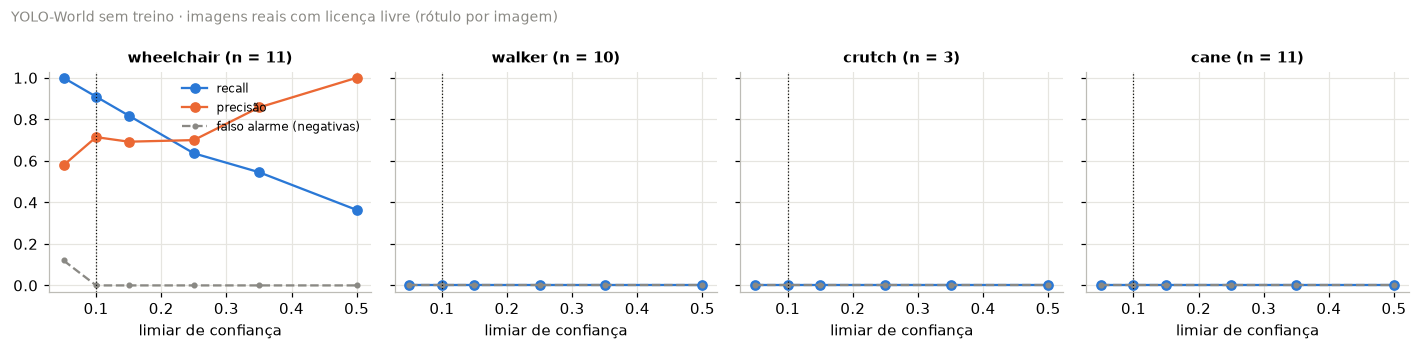

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, c in zip(axes, AUX):
    a = aval[aval["classe"] == c]
    ax.plot(a["limiar"], a["recall"], color=AZUL, marker="o", label="recall")
    ax.plot(a["limiar"], a["precisão"], color=LARANJA, marker="o", label="precisão")
    ax.plot(a["limiar"], a["falso alarme nas negativas"], color=CINZA, ls="--", marker=".", label="falso alarme (negativas)")
    ax.axvline(vs.CONF_MIN_AUXILIO, color="#0b0b0b", lw=0.8, ls=":")
    ax.set_title(f"{c} (n = {int(a['positivas'].iloc[0])})", fontsize=10); ax.set_xlabel("limiar de confiança")
    ax.set_ylim(-0.03, 1.03)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("YOLO-World sem treino · imagens reais com licença livre (rótulo por imagem)", x=0.01, ha="left", fontsize=9, color=CINZA)
fig.tight_layout(); fig.savefig(EVID / "07_avaliacao_pcd.png", dpi=150, bbox_inches="tight", facecolor="white"); plt.show()

### 6.1 O zero vem da palavra? Teste com sinônimos sem ambiguidade

"walker" também quer dizer "pessoa que caminha" e "cane" também é "candy cane". Repetimos a avaliação dando ao
YOLO-World vários nomes por classe e usando a maior confiança entre eles. Se o recall subir, parte do zero era do texto,
não do modelo.

In [10]:
SINONIMOS = {"wheelchair": ["wheelchair"], "walker": ["walker", "rollator", "walking frame", "zimmer frame"],
             "crutch": ["crutch", "crutches", "forearm crutch"], "cane": ["cane", "walking stick", "white cane", "blind cane"]}
modelo_s = YOLOWorld(str(detector.PESOS)); modelo_s.set_classes(["person", *sum(SINONIMOS.values(), [])])
inverso = {n: c for c, ns in SINONIMOS.items() for n in ns}
esc_s = []
for r in rot.itertuples():
    res = modelo_s.predict(str(PASTA / "img" / r.arquivo), conf=0.01, verbose=False)[0]
    s = {c: 0.0 for c in AUX}
    for c, p in zip(res.boxes.cls.int().tolist(), res.boxes.conf.tolist()):
        if res.names[c] in inverso: s[inverso[res.names[c]]] = max(s[inverso[res.names[c]]], p)
    esc_s.append(s)
esc_s = pd.DataFrame(esc_s)
comp = []
for c in AUX:
    real = rot[c] == 1
    for nome, e in [("nome simples", esc), ("com sinônimos", esc_s)]:
        for lim in [0.10, 0.25]:
            pred = e[c] >= lim
            tp, fp = int((pred & real).sum()), int((pred & ~real).sum())
            comp.append({"classe": c, "vocabulário": nome, "limiar": lim, "recall": tp / max(int(real.sum()), 1),
                         "precisão": tp / (tp + fp) if tp + fp else np.nan, "falso alarme": float(pred[negativas].mean())})
comp = pd.DataFrame(comp)
comp.to_csv(EVID / "07_avaliacao_pcd_sinonimos.csv", sep=";", index=False, encoding="utf-8-sig")
comp.round(2).pivot_table(index=["classe", "vocabulário"], columns="limiar", values=["recall", "precisão", "falso alarme"])

falso alarme      precisão      recall      
limiar                           0.10 0.25     0.10 0.25   0.10  0.25
classe     vocabulário                                               
cane       com sinônimos          0.0  0.0     0.67  1.0   0.18  0.09
           nome simples           0.0  0.0      NaN  NaN   0.00  0.00
crutch     com sinônimos          0.0  0.0      NaN  NaN   0.00  0.00
           nome simples           0.0  0.0      NaN  NaN   0.00  0.00
walker     com sinônimos          0.0  0.0     0.67  1.0   0.20  0.10
           nome simples           0.0  0.0      NaN  NaN   0.00  0.00
wheelchair com sinônimos          0.0  0.0     0.73  0.8   1.00  0.73
           nome simples           0.0  0.0     0.71  0.7   0.91  0.64

**Leitura:** o vídeo não tem nenhuma pessoa com auxílio de mobilidade, então o desempenho foi medido em 58 fotos
reais com licença livre. A cadeira de rodas funciona: no limiar 0,25, recall 0,64 e precisão 0,70 com o nome simples
(0,73 e 0,80 com sinônimos), sem falso alarme nas 25 imagens sem auxílio. Andador, muleta e bengala praticamente não
são reconhecidos (recall entre 0 e 0,20, mesmo com sinônimos): são objetos finos, pequenos e parecidos com outras
coisas, e o YOLO-World não foi treinado para eles. O sistema, portanto, **não deve prometer** identificar quem usa
bengala ou andador; o caminho para isso é o ajuste fino com imagens. **Atualização (13/11):** com estes números, o limiar dos auxílios passou para 0,10 (10 de 11 cadeirantes, sem alarme nas negativas; otimista, pois foi escolhido nestas mesmas fotos), e a cadeira de rodas ganhou um modelo ajustado no Colab (notebook 08), demonstrado em vídeo no notebook 09. Andador, muleta e bengala seguem sem dados de treino.

## 7. Eventos no banco

In [11]:
eventos = vs.eventos_de(vs.travessias(dets, faixa, FPS, PCD), conf_l, bloq_l, PCD, dets, faixa, FPS)
con = sqlite3.connect(PROCESSED / "seguranca_viaria.db")
vs.migrar(con)
# reprocessar substitui os eventos anteriores DESTE vídeo (execuções com parâmetros antigos não ficam no banco)
novos = vs.substituir_eventos(con, eventos, VIDEO_ID)
repetidos = vs.gravar_eventos(con, eventos, VIDEO_ID)   # gravar de novo o mesmo lote não duplica nada
print(f"eventos gerados: {len(eventos)} | gravados: {novos} | segunda gravação do mesmo lote: {repetidos} (idempotente)")
display(pd.read_sql_query("SELECT tipo, COUNT(*) AS eventos FROM eventos WHERE origem = 'yolo' GROUP BY tipo ORDER BY eventos DESC", con))
display(pd.read_sql_query("SELECT timestamp, tipo, valor, payload_json FROM eventos WHERE origem = 'yolo' LIMIT 3", con))
con.close()

eventos gerados: 104 | gravados: 104 | segunda gravação do mesmo lote: 0 (idempotente)


,tipo,eventos
0,pedestre_na_faixa,48
1,travessia,46
2,conflito_veiculo_pedestre,7
3,bloqueio_faixa,2
4,contagem_minuto,1


,timestamp,tipo,valor,payload_json
0,2026-11-13T12:53:11-03:00,pedestre_na_faixa,None,"{""demonstracao"": true, ""video_id"": ""cdmx_pexel..."
1,2026-11-13T12:53:11-03:00,pedestre_na_faixa,None,"{""demonstracao"": true, ""video_id"": ""cdmx_pexel..."
2,2026-11-13T12:53:11-03:00,pedestre_na_faixa,None,"{""demonstracao"": true, ""video_id"": ""cdmx_pexel..."


## 8. Evidências (tudo borrado)

In [12]:
from PIL import Image
quadro_pico = int(det_df[det_df["classe"] == "person"].groupby("quadro").size().idxmax())
ini = max(0, quadro_pico - 60)
_, _, _, gen = vs.ler_video(VIDEO)
gif, saida_video = [], []
for i, img in enumerate(gen):
    if ini <= i < ini + 120 and (i % 4 == 0 or i == ini + 60):
        dq = [d for d in dets_todas if d.quadro == i - (i % A_CADA)]
        b = vs.anotar(img, dq, faixa, AUXILIOS, CONF_POR_QUADRO.get(i), privadas_extra=PRIV_EXTRA.get(i - (i % A_CADA), []))
        if i == ini + 60:
            vs.salvar_quadro(b, dq, EVID / "07_quadro_anotado.jpg")
        if i % 4 == 0:
            gif.append(Image.fromarray(cv2.cvtColor(cv2.resize(b, (360, 640)), cv2.COLOR_BGR2RGB)))
    if i >= ini + 120:
        break
gif[0].save(EVID / "07_faixa_anotada.gif", save_all=True, append_images=gif[1:], duration=130, loop=0)
pd.DataFrame([{"métrica": k, "valor": v} for k, v in {
    "quadros por segundo em CPU": round(FPS_PROC, 2), "travessias concluídas": int((trav["status"] == "concluida").sum()) if len(trav) else 0,
    "velocidade mediana (m/s)": round(float(ok["velocidade_ms"].median()), 2) if len(ok) else None,
    "% abaixo de 1,2 m/s": round(float(ok["abaixo_1_2_ms"].mean()) * 100, 1) if len(ok) else None,
    "conflitos": len(conf_l), "bloqueios": len(bloq_l), "pessoas PCD no vídeo": len(PCD)}.items()]).to_csv(
    EVID / "07_metricas.csv", sep=";", index=False, encoding="utf-8-sig")
aval.round(3).to_csv(EVID / "07_avaliacao_pcd.csv", sep=";", index=False, encoding="utf-8-sig")
print("evidências:", sorted(p.name for p in EVID.glob("07_*")))

evidências: ['07_avaliacao_pcd.csv', '07_avaliacao_pcd.png', '07_avaliacao_pcd_sinonimos.csv', '07_conferencia_manual.csv', '07_conferencia_quadros.jpg', '07_faixa_anotada.gif', '07_metricas.csv', '07_quadro_anotado.jpg', '07_testes_visao.txt', '07_travessias.png']


In [13]:
# Vídeo completo de saída (borrado e anotado) para o vídeo de 5 min da entrega: fica fora do Git (*.mp4 no .gitignore)
def quadros_borrar():
    _, _, _, g = vs.ler_video(VIDEO)
    for i, img in enumerate(g):
        dq = [d for d in dets_todas if d.quadro == i - (i % A_CADA)]
        yield vs.anotar(img, dq, faixa, AUXILIOS, CONF_POR_QUADRO.get(i), privadas_extra=PRIV_EXTRA.get(i - (i % A_CADA), [])), dq
saida = vs.gravar_video_borrado(quadros_borrar(), PROCESSED / "visao_cdmx_borrado.mp4", FPS)
print("vídeo borrado:", saida.relative_to(ROOT), f"({saida.stat().st_size / 1e6:.0f} MB)")

vídeo borrado: data\processed\visao_cdmx_borrado.mp4 (79 MB)


## 9. Limitações

**Limitações:**
- **Demonstração, não o piloto:** o vídeo é de uma faixa na Cidade do México, não do Largo da Concórdia. Todo evento
  gravado tem `demonstracao: true`.
- **Um vídeo de 55 s**, de dia e com tempo bom: números como "por hora" não são estimativas.
- **Escala aproximada:** a largura da faixa (6,7 m no polígono) foi estimada pelas listras; a velocidade herda esse
  erro.
- **Fragmentação do rastreamento:** uma pessoa pode virar mais de um identificador; contagens de pessoas são de
  identificadores.
- **Auxílios de mobilidade:** só a cadeira de rodas é detectada com alguma confiança.
- **Desempenho:** 2,7 quadros/s em CPU.
- **Privacidade (LGPD):** não há reconhecimento facial; cabeças e placas são pixeladas antes de qualquer imagem ser
  salva, e o banco guarda só números e categorias.